In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

def min_max_scaler(min, max, x):
    return (x - min) / (max - min)

np.random.seed(0)

In [2]:
theta_bg = 10+0.9
n_gaussian_dim = 2
n_signal_events = 100000
n_signal_hypothesis = 10
n_bg_events = 4*n_signal_events
theta_signal = np.linspace(2,8,10)
min_theta = min(theta_signal)
max_theta = max(theta_signal)
if len(theta_signal) != n_signal_hypothesis:
    raise ValueError("Length of theta_signal must be equal to n_signal_hypothesis")

# Create the data
signal_X = np.empty(shape = (0, n_gaussian_dim + 1 + 1))
signal_category = np.empty(shape=(0,1),dtype = np.float32)
category = 1
for itheta in theta_signal:
    new_signal_X = np.random.normal(loc = itheta, scale = 1.0, size = (n_signal_events, n_gaussian_dim))
    new_signal_theta = np.full(shape = (n_signal_events, 1), fill_value = min_max_scaler(min_theta, max_theta, itheta))
    weight_signal = np.full_like(new_signal_theta, fill_value=1.0)
    new_signal_data = np.concatenate((new_signal_X,new_signal_theta, weight_signal), axis=1)
    signal_X = np.concatenate((signal_X, new_signal_data), axis = 0).astype(np.float32)
    signal_category = np.concatenate((signal_category, np.full(shape=(n_signal_events,1), fill_value=category)), axis=0)
    category += 1

bg_X = 10*np.random.random(size = (n_bg_events, n_gaussian_dim))
bg_theta = np.random.choice(signal_X[:,-2], size=(n_bg_events, 1)).astype(np.float32)
weight_bg = np.full_like(bg_theta, fill_value=0.25)
bg_X = np.concatenate((bg_X, bg_theta, weight_bg), axis = 1)
print("Signal data shape:", signal_X.shape)
print("Background data shape:", bg_X.shape)

# Create the labels
signal_y = np.ones(shape = (signal_X.shape[0],1), dtype = np.float32)
signal_y = np.concatenate((signal_y,signal_category),axis=1)
bg_y = np.zeros(shape = (bg_X.shape[0],1), dtype = np.float32)
bg_category = np.full(shape=(n_bg_events,1),fill_value=-1,dtype = np.float32)
bg_y = np.concatenate((bg_y,bg_category), axis=1)

# Combine datasets
X = np.concatenate((signal_X, bg_X), axis = 0)
y = np.concatenate((signal_y, bg_y), axis = 0)

Signal data shape: (1000000, 4)
Background data shape: (400000, 4)


In [3]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using mps device


In [4]:
# Split in train, val, test
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
train_indices, test_indices = next(sss.split(X, y))

X_train, y_train = X[train_indices], y[train_indices]
X_temp, y_temp = X[test_indices], y[test_indices]
X_val, X_test, y_val, y_test     = train_test_split(X_temp, y_temp, test_size=0.5, shuffle=True)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
scaler = ColumnTransformer(
    [('Std Scaler',StandardScaler(), list(range(n_gaussian_dim))),
    ],
    remainder='passthrough'
)

X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

# As tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_val_tensor   = torch.tensor(X_val, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_val_tensor   = torch.tensor(y_val, dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test, dtype=torch.float32)

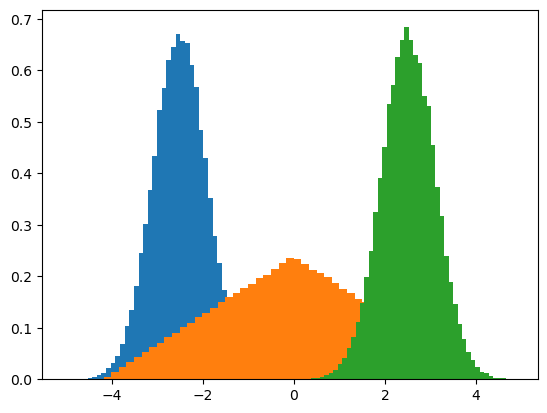

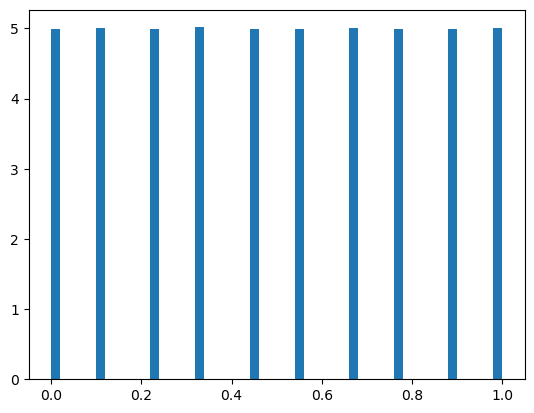

In [5]:
plt.hist(X_train[y_train[:,1]==1][:,1]+X_train[y_train[:,1]==1][:,0],bins=50, density= True)
plt.hist(X_train[y_train[:,1]==-1][:,1]+X_train[y_train[:,1]==-1][:,0],bins=50, density= True)
plt.hist(X_train[y_train[:,1]==10][:,1]+X_train[y_train[:,1]==10][:,0],bins=50, density= True)
plt.show()

plt.hist(X_train[:,-2],bins=50, density= True)
plt.show()

In [6]:
# Define the Classifier
class Classifier(nn.Module):
    def __init__(self, x_dim, theta_dim = 0, hidden_dim = 4):
        super(Classifier, self).__init__()
        self.theta_dim = theta_dim
        if self.theta_dim == 0:
            print("NN: Using non-parametric model.")
        else:
            print("NN: Using parametric model with theta dimension =", theta_dim)
        self.net = nn.Sequential(
            nn.Linear(x_dim + theta_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2*hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=0.05),
            nn.Linear(2*hidden_dim, 2*hidden_dim),
            nn.ReLU(),
            nn.Linear(2*hidden_dim, 1),
        )

    def forward(self, X):
        logits = self.net(X)
        return logits

In [7]:
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train_tensor,
                              y_train_tensor)
val_dataset   = TensorDataset(X_val_tensor,
                              y_val_tensor)
test_dataset  = TensorDataset(X_test_tensor,
                              y_test_tensor)

# Create DataLoader objects for training, validation, and testing in batches
train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=True, num_workers=6, persistent_workers=True, drop_last=True)
val_loader   = DataLoader(val_dataset, batch_size=1024, shuffle=False, num_workers=6, persistent_workers=True, drop_last=True)
test_loader  = DataLoader(test_dataset, batch_size=1024, shuffle=False, num_workers=6)

In [8]:
import torch.optim as optim
model = Classifier(x_dim = n_gaussian_dim, theta_dim = 1, hidden_dim = 8)
criterion = nn.BCELoss(reduction='none')
optimizer_parametric = optim.AdamW(model.parameters(), lr=0.0002, weight_decay=0.001)

NN: Using parametric model with theta dimension = 1


In [9]:
# Training loop on mini-batches with loss stored for plotting
train_losses = []
val_losses = []
num_epochs = 80

model.to(device)

for epoch in range(num_epochs):
    model.train()
    # run over batches of data
    running_loss = 0.0
    for inputs, targets in train_loader:
        optimizer_parametric.zero_grad()
        inputs_device = inputs.to(device)
        targets_device = targets[:,0].to(device)
        outputs = model(inputs_device[:,:-1])
        outputs = torch.sigmoid(outputs)
        weights = inputs_device[:,-1]
        loss = weights*criterion(outputs.squeeze(), targets_device)
        loss = torch.sum(loss)/len(loss)
        loss.backward()
        optimizer_parametric.step()
        running_loss += loss.item()

    # compute avergae loss over all batches
    train_loss = running_loss / len(train_loader)
    train_losses.append(train_loss)

    # Validation step
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs_device = inputs.to(device)
            targets_device = targets[:,0].to(device)
            outputs = model(inputs_device[:,:-1])
            outputs = torch.sigmoid(outputs)
            weights = inputs_device[:,-1]
            loss = weights*criterion(outputs.squeeze(), targets_device)
            loss = torch.sum(loss)/len(loss)
            val_loss += loss.item()

    val_loss /= len(val_loader)
    val_losses.append(val_loss)

    print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

Epoch 1/80, Train Loss: 0.3029, Val Loss: 0.2231
Epoch 2/80, Train Loss: 0.1835, Val Loss: 0.1332
Epoch 3/80, Train Loss: 0.1235, Val Loss: 0.1116
Epoch 4/80, Train Loss: 0.1078, Val Loss: 0.1007
Epoch 5/80, Train Loss: 0.0988, Val Loss: 0.0937
Epoch 6/80, Train Loss: 0.0939, Val Loss: 0.0911
Epoch 7/80, Train Loss: 0.0922, Val Loss: 0.0903
Epoch 8/80, Train Loss: 0.0916, Val Loss: 0.0899
Epoch 9/80, Train Loss: 0.0912, Val Loss: 0.0897
Epoch 10/80, Train Loss: 0.0909, Val Loss: 0.0895
Epoch 11/80, Train Loss: 0.0906, Val Loss: 0.0895
Epoch 12/80, Train Loss: 0.0905, Val Loss: 0.0893
Epoch 13/80, Train Loss: 0.0903, Val Loss: 0.0893
Epoch 14/80, Train Loss: 0.0902, Val Loss: 0.0892
Epoch 15/80, Train Loss: 0.0902, Val Loss: 0.0892
Epoch 16/80, Train Loss: 0.0901, Val Loss: 0.0891
Epoch 17/80, Train Loss: 0.0900, Val Loss: 0.0891
Epoch 18/80, Train Loss: 0.0899, Val Loss: 0.0890
Epoch 19/80, Train Loss: 0.0898, Val Loss: 0.0891
Epoch 20/80, Train Loss: 0.0898, Val Loss: 0.0890
Epoch 21/

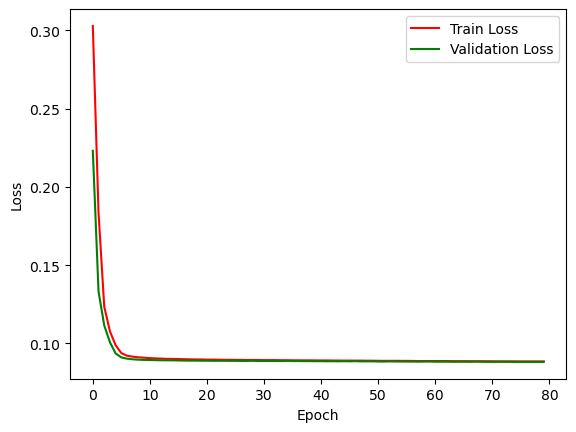

In [10]:
# Plot loss function for training and validation sets
plt.plot(train_losses, label='Train Loss', color='red')
plt.plot(val_losses, label='Validation Loss', color='green')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train Loss', 'Validation Loss'])
#plt.yscale('log')
plt.show()

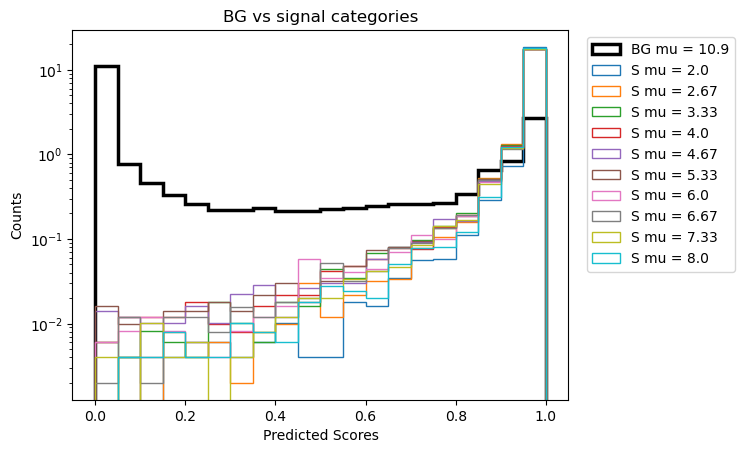

In [11]:
model.to('cpu')
model.eval()
y_pred = torch.sigmoid(model(X_test_tensor[:,:-1]).detach())

# Filter the predicted events for true Signal and true Background
sb_label = y_test[:,0]
category_label = y_test[:,1]
true_bkg = y_pred[sb_label==0].numpy()

i_category = 1
plt.hist(true_bkg, bins=20,range=(0,1), histtype='step', label='Background', density=True, color='black', linewidth=2.5)
plt.xlabel("Predicted Scores")
plt.ylabel("Counts")
plt.title("BG vs signal categories")
#plt.xlim((0.7,0.9))
plt.yscale('log')
signal_legends = []
for i in range(1,11):
    # Plot the predicted scores for both true Signal and true Background events
    true_signal = y_pred[category_label==i_category].numpy()
    plt.hist(true_signal, bins=20, range=(0,1), histtype='step', label='Signal', density=True)
    signal_legends.append(f"S mu = %s" % str(round(theta_signal[i-1],2)))
    i_category += 1

plt.legend(["BG mu = 10.9"]+signal_legends,bbox_to_anchor=(1.35, 1), loc='upper right')
plt.show()

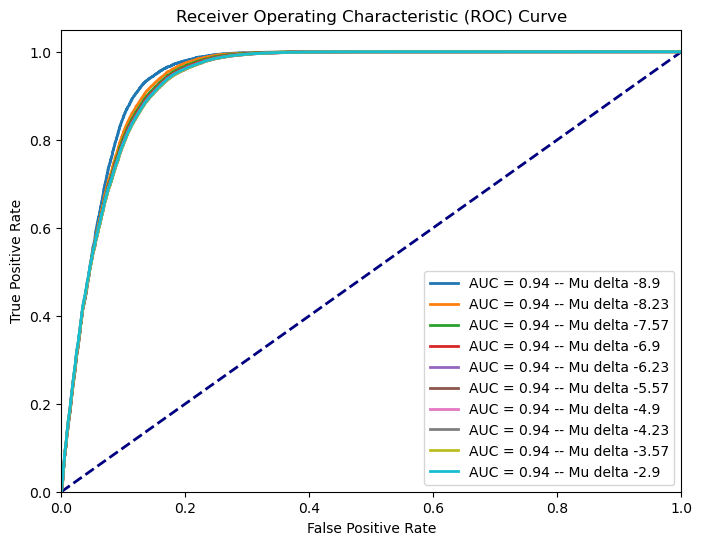

In [12]:
# Compute ROC curve
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Random classifier line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')

for icat in range(1,11):
    y_pred_cat = y_pred[category_label<=icat].numpy()
    y_test_cat = y_test[category_label<=icat]
    fpr, tpr, thresholds = roc_curve(y_test_cat[:,0], y_pred_cat)
    # Compute AUC (Area Under Curve)
    roc_auc = auc(fpr, tpr)
    # Plot ROC curve
    plt.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.2f} -- Mu delta {round(- theta_bg + theta_signal[icat-1],2)}')
    
plt.legend(loc='lower right')
plt.show()

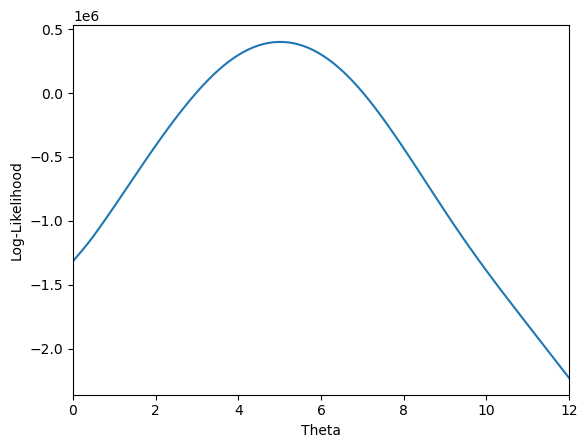

MLE estimate for theta: 4.96969696969697


In [13]:
def ratio(x_obs, theta):
    X = torch.cat([x_obs, theta], dim=1)
    logits = model(X)
    s = torch.sigmoid(logits)
    r = s / (1 - s)
    return r

def log_likelihood(theta, X_obs):
    # X_obs: shape [N, x_dim]
    thetas = theta.unsqueeze(0).expand(len(X_obs), -1)
    r_vals = ratio(X_obs, thetas)
    return torch.sum(torch.log(r_vals))



new_data =  np.random.normal(loc = 5, scale = 1.0, size = (n_signal_events, n_gaussian_dim)).astype(np.float32)
new_data = np.concatenate((new_data, np.full((n_signal_events, 1), fill_value=0.0), np.full((n_signal_events, 1), fill_value=11)), axis=1).astype(np.float32)
new_data   = scaler.transform(new_data)
new_data = new_data[:,:-2]
new_X = torch.tensor(new_data, requires_grad=False)

# Generate new data for parameter estimation
new_data =  np.random.normal(loc = 5, scale = 1.0, size = (n_signal_events, n_gaussian_dim)).astype(np.float32)
log_likelihoods = []
x = np.linspace(0,12,100)
for ix in x: # Scan over different theta values
    theta_tensor = torch.tensor([min_max_scaler(min_theta, max_theta, ix)], requires_grad=False, dtype=torch.float32)
    llh = log_likelihood(theta_tensor, new_X) # Evaluate using the ML model!
    log_likelihoods.append(llh.item())

plt.plot(x, log_likelihoods)
plt.xlabel("Theta")
plt.ylabel("Log-Likelihood")
plt.xlim((min(x),max(x)))
plt.show()

# Get the MLE estimate for theta
np.argmax(log_likelihoods)
theta_mle = x[np.argmax(log_likelihoods)]
print("MLE estimate for theta:", theta_mle)

other_log_likelihoods = log_likelihoods

In [18]:
theta_guess = torch.tensor([6.8], requires_grad=True)

optimizer_theta = torch.optim.Adam([theta_guess], lr=1e-3)

for step in range(100):
    optimizer_theta.zero_grad()
    ll = -log_likelihood(theta_guess, new_X)
    loss_theta = ll  # minimize log-likelihood ratio
    loss_theta.backward()
    optimizer_theta.step()

    if step % 20 == 0:
        print(step, theta_guess.item(), ll.item())

theta_mle = theta_guess.detach()
print("MLE:", theta_mle)

0 6.800000190734863 234355.3125
20 6.800000190734863 234355.3125
40 6.800000190734863 234355.3125
60 6.800000190734863 234355.3125
80 6.800000190734863 234355.3125
MLE: tensor([6.8000])


In [84]:
class Encoder(nn.Module):
    def __init__(self, x_dim, hidden_dim=16, latent_dim=8):
        super(Encoder, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(x_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
            nn.LayerNorm(latent_dim),
        )
    def forward(self, X):
        latent = self.net(X)
        return latent

class ClassifierHead(nn.Module):
    def __init__(self, latent_dim=8, theta_dim=1, hidden_dim=16):
        super(ClassifierHead, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim + theta_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=0.1),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=0.1),
            nn.Linear(hidden_dim, 1),
        )
    def forward(self, latent):
        logits = self.net(latent)
        return logits

class DecorrelatorHead(nn.Module):
    def __init__(self, latent_dim=8, hidden_dim=32, theta_dim=1):
        super(DecorrelatorHead, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, theta_dim),
        )
    def forward(self, latent):
        theta = self.net(latent)
        return theta

# --------------------------
# Gradient Reversal Layer
# --------------------------
class GradientReversalFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lambd):
        ctx.lambd = lambd
        return x.view_as(x)
    @staticmethod
    def backward(ctx, grad_output):
        return grad_output.neg() * ctx.lambd, None

def grad_reverse(x, lambd=1.0):
    return GradientReversalFunction.apply(x, lambd)


def reset_adversary(adversary, adv_optimizer, optimizer_kwargs=None, init_fn=None):
    # Reinitialize weights
    if init_fn is None:
        def init_fn(m):
            if hasattr(m, 'reset_parameters'):
                m.reset_parameters()
    adversary.apply(init_fn)
    
    # Recreate optimizer to clear momentum, Adam buffers, etc.
    new_adv_optimizer = type(adv_optimizer)(
        adversary.parameters(),
        **optimizer_kwargs
    )
    return new_adv_optimizer

In [85]:
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

encoder = Encoder(x_dim = n_gaussian_dim)
classifier_head = ClassifierHead()
decorrelator_head = DecorrelatorHead()


criterion_classifier = nn.BCELoss(reduction='none')
criterion_adversarial = nn.L1Loss(reduction='none')
optimizer_classifier = optim.AdamW(list(encoder.parameters()) + list(classifier_head.parameters()), lr=0.0002, weight_decay=0.001)
optimizer_adversarial = optim.AdamW(decorrelator_head.parameters(), lr=0.0002, weight_decay=0.001)

train_dataset = TensorDataset(X_train_tensor,
                              y_train_tensor)
val_dataset   = TensorDataset(X_val_tensor,
                              y_val_tensor)
test_dataset  = TensorDataset(X_test_tensor,
                              y_test_tensor)

# Create DataLoader objects for training, validation, and testing in batches
train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=True, num_workers=8, persistent_workers=True, drop_last=True)
val_loader   = DataLoader(val_dataset, batch_size=1024, shuffle=False, num_workers=8, persistent_workers=True, drop_last=True)
test_loader  = DataLoader(test_dataset, batch_size=1024, shuffle=False, num_workers=8)

def adv_lambda_scheduler(epoch, max_adv_lambda = 0.5, start_adv_lambda = 0.05, n_waming_up_epochs = 10):
    if epoch > n_waming_up_epochs:
        return max_adv_lambda
    else:
        adv_lambda = start_adv_lambda + epoch * (max_adv_lambda - start_adv_lambda) / n_waming_up_epochs
        return adv_lambda

In [86]:
# Training loop on mini-batches with loss stored for plotting
train_losses_adversarial = []
train_losses_classifier = []
R2_train = []
R2_val = []
val_losses = []
num_epochs = 60
adv_weight = 0.5

encoder.to(device)
classifier_head.to(device)
decorrelator_head.to(device)

for epoch in range(num_epochs):
    running_loss_adversarial = 0.0
    running_loss_classifier = 0.0
    running_R2 = 0.0

    adv_lambda = adv_lambda_scheduler(epoch)

    # Reset adversary condition
    if epoch % 8 == 0 and epoch != 0:
        optimizer_adversarial = reset_adversary(decorrelator_head, optimizer_adversarial, optimizer_kwargs={'lr':0.0004, 'weight_decay':0.001})
        print("Adversary reset.")

    for inputs, targets in train_loader:
        inputs_device = inputs.to(device)
        targets_device = targets[:,0].to(device)

        ###############################
        # 1. ADVERSARY STEP (update only decorrelator)
        ###############################
        weights = inputs_device[:, -1]
        
        # Disable encoder gradients so adversary does not update encoder
        encoder.eval()
        with torch.no_grad():
            z_no_grad = encoder(inputs_device[:, :-2])

        decorrelator_head.train()
        optimizer_adversarial.zero_grad()

        decorrelator_output = decorrelator_head(z_no_grad)
        loss_adv_only = (weights * criterion_adversarial(decorrelator_output.squeeze(), inputs_device[:, -2])).mean()

        loss_adv_only.backward()
        optimizer_adversarial.step()

        ###############################
        # 2. MAIN STEP (update encoder + classifier)
        ###############################
        # IMPORTANT: DO NOT zero_grad on optimizer_adversarial again here

        encoder.train()
        optimizer_classifier.zero_grad()
        
        # normal forward with gradient enabled
        z = encoder(inputs_device[:, :-2])
        theta = inputs_device[:, -2].reshape(-1,1)

        classifier_output = classifier_head(torch.cat([z, theta], dim=1))
        classifier_output = torch.sigmoid(classifier_output)

        loss_classifier = (weights * criterion_classifier(classifier_output.squeeze(), targets_device)).mean()

        # adversarial loss via GRL (gradient into encoder reversed)
        z_rev = grad_reverse(z, lambd=adv_lambda)
        decorrelator_output = decorrelator_head(z_rev)
        loss_adv_for_encoder = (weights * criterion_adversarial(decorrelator_output.squeeze(), inputs_device[:, -2])).mean()

        loss = loss_classifier + adv_weight * loss_adv_for_encoder
        loss.backward()

        optimizer_classifier.step()

        running_loss_adversarial += loss_adv_only.item()
        running_loss_classifier += loss_classifier.item()
        # Calculate R2 for monitoring
        r2 = 1 - torch.sum((decorrelator_output.squeeze() - inputs_device[:, -2])**2) / torch.sum((inputs_device[:, -2] - torch.mean(inputs_device[:, -2]))**2)
        running_R2 += r2.item()

    # compute avergae loss over all batches
    train_losss_adversarial = running_loss_adversarial / len(train_loader)
    train_loss_classifier = running_loss_classifier / len(train_loader)
    train_losses_adversarial.append(train_losss_adversarial)
    train_losses_classifier.append(train_loss_classifier)
    r2_train = running_R2 / len(train_loader)
    R2_train.append(r2_train)

    # Validation step
    encoder.eval()
    classifier_head.eval()
    val_loss = 0.0
    running_R2_val = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs_device = inputs.to(device)
            targets_device = targets[:,0].to(device)
            z = encoder(inputs_device[:, :-2])
            theta = inputs_device[:, -2].reshape(inputs_device[:, -2].shape[0],1)
            classifier_output = classifier_head(torch.cat([z,theta],dim=1))
            classifier_output = torch.sigmoid(classifier_output)
            weights = inputs_device[:,-1]
            loss_classifier = weights*criterion_classifier(classifier_output.squeeze(), targets_device)
            loss_classifier = loss_classifier.mean()

            # Calculate R2 for monitoring
            decorrelator_output = decorrelator_head(z)
            r2 = 1 - torch.sum((decorrelator_output.squeeze() - inputs_device[:, -2])**2) / torch.sum((inputs_device[:, -2] - torch.mean(inputs_device[:, -2]))**2)
            running_R2_val += r2.item()
        
            val_loss += loss_classifier.item()


    val_loss /= len(val_loader)
    r2_val = running_R2_val / len(val_loader)
    R2_val.append(r2_val)
    val_losses.append(val_loss)
    print(f"Lambda reversal = {adv_lambda}")
    print(f"Epoch {epoch+1}/{num_epochs} -> Classifier Loss: {train_loss_classifier:.4f}, Val: {val_loss:.4f} , Adversarial Loss: {train_losss_adversarial:.4f}, R2 Train: {r2_train:.4f}, R2 Val: {r2_val:.4f}")

Lambda reversal = 0.05
Epoch 1/60 -> Classifier Loss: 0.1941, Val: 0.1124 , Adversarial Loss: 0.0984, R2 Train: 0.3162, R2 Val: 0.4207
Lambda reversal = 0.095
Epoch 2/60 -> Classifier Loss: 0.0986, Val: 0.0924 , Adversarial Loss: 0.0843, R2 Train: 0.4173, R2 Val: 0.4169
Lambda reversal = 0.14
Epoch 3/60 -> Classifier Loss: 0.0913, Val: 0.0902 , Adversarial Loss: 0.0840, R2 Train: 0.4214, R2 Val: 0.4264
Lambda reversal = 0.185
Epoch 4/60 -> Classifier Loss: 0.0900, Val: 0.0893 , Adversarial Loss: 0.0839, R2 Train: 0.4230, R2 Val: 0.4251
Lambda reversal = 0.22999999999999998
Epoch 5/60 -> Classifier Loss: 0.0894, Val: 0.0890 , Adversarial Loss: 0.0838, R2 Train: 0.4233, R2 Val: 0.4332
Lambda reversal = 0.275
Epoch 6/60 -> Classifier Loss: 0.0892, Val: 0.0902 , Adversarial Loss: 0.0838, R2 Train: 0.4235, R2 Val: 0.4227
Lambda reversal = 0.32
Epoch 7/60 -> Classifier Loss: 0.0890, Val: 0.0887 , Adversarial Loss: 0.0837, R2 Train: 0.4237, R2 Val: 0.4285
Lambda reversal = 0.365
Epoch 8/60 ->

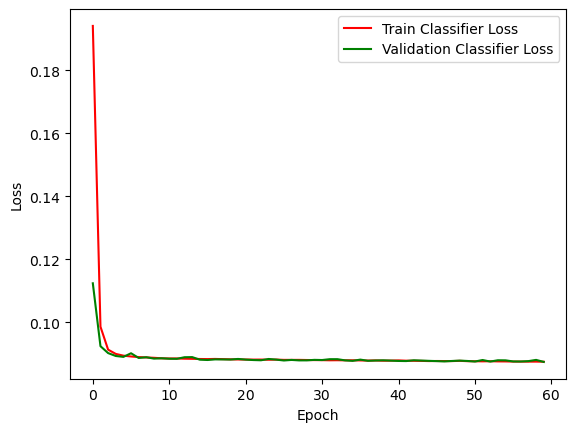

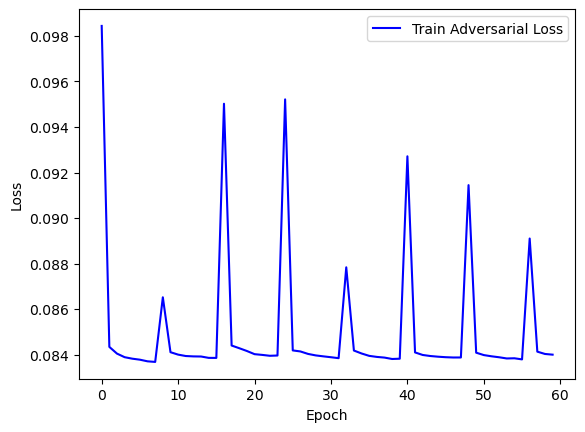

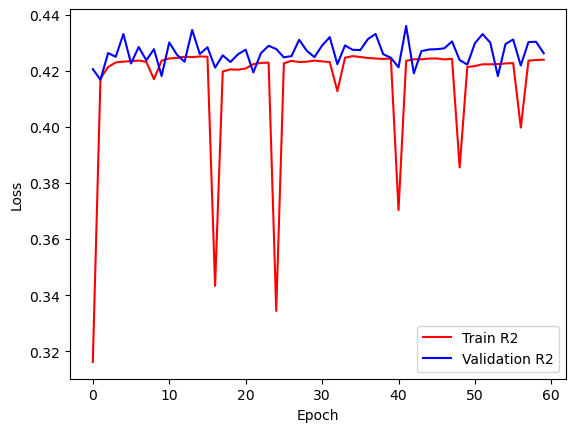

In [89]:
# Plot loss function for training and validation sets
plt.plot(train_losses_classifier, label='Train Classifier Loss', color='red')
plt.plot(val_losses, label='Validation Classifier Loss', color='green')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train Classifier Loss', 'Validation Classifier Loss'])
#plt.yscale('log')
plt.show()

# Plot loss function for training and validation sets
plt.plot(train_losses_adversarial, label='Train Adversarial Loss', color='blue')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train Adversarial Loss'])
#plt.yscale('log')
plt.show()


# Plot loss function for training and validation sets
plt.plot(R2_train, label='Train R2', color='red')
plt.plot(R2_val, label='Validation R2', color='blue')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train R2', 'Validation R2'])
#plt.yscale('log')
plt.show()

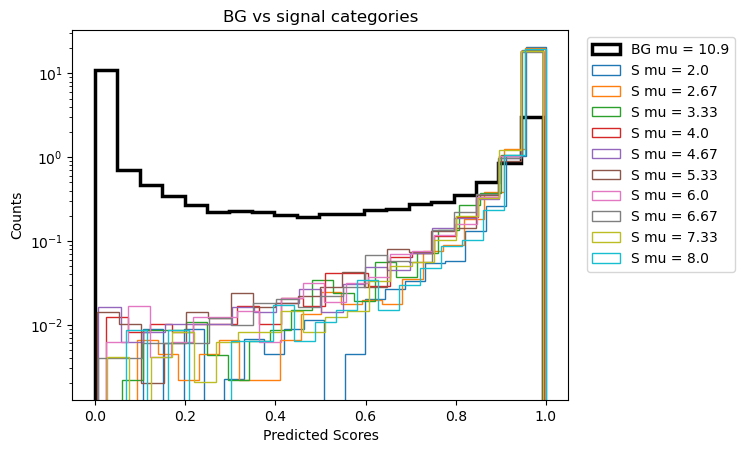

In [90]:
encoder.to('cpu')
classifier_head.to('cpu')
encoder.eval()
classifier_head.eval()

y_pred = encoder(X_test_tensor[:,:-2])
theta_ref = X_test_tensor[:,-2].reshape(X_test_tensor.shape[0],1)
y_pred = torch.cat([y_pred, theta_ref], dim=1)
y_pred = classifier_head(y_pred)
y_pred = torch.sigmoid(y_pred.detach())


sb_label = y_test[:,0]
category_label = y_test[:,1]
true_bkg = y_pred[sb_label==0].numpy()

i_category = 1
plt.hist(true_bkg, bins=20, histtype='step', label='Background', density=True, color='black', linewidth=2.5)
plt.xlabel("Predicted Scores")
plt.ylabel("Counts")
plt.title("BG vs signal categories")
#plt.xlim((0.7,0.9))
plt.yscale('log')
signal_legends = []
for i in range(1,11):
    # Plot the predicted scores for both true Signal and true Background events
    true_signal = y_pred[category_label==i_category].numpy()
    plt.hist(true_signal, bins=20, histtype='step', label='Signal', density=True)
    signal_legends.append(f"S mu = %s" % str(round(theta_signal[i-1],2)))
    i_category += 1

plt.legend(["BG mu = 10.9"]+signal_legends,bbox_to_anchor=(1.35, 1), loc='upper right')
plt.show()

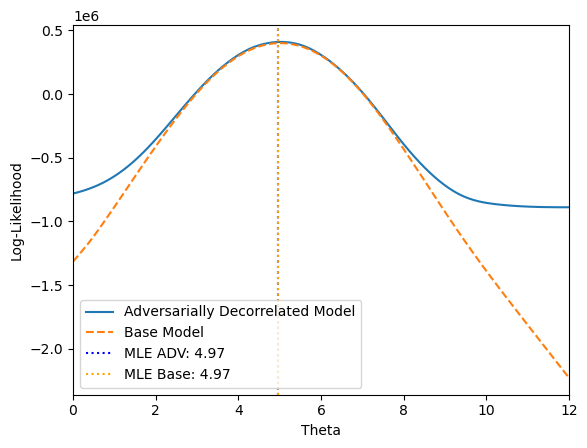

In [91]:
def ratio(x_obs, theta):
    z = encoder(x_obs)
    X = torch.cat([z, theta], dim=1)
    logits = classifier_head(X)
    s = torch.sigmoid(logits)
    r = s / (1 - s)
    return r

def log_likelihood(theta, X_obs):
    # X_obs: shape [N, x_dim]
    thetas = theta.unsqueeze(0).expand(len(X_obs), -1)
    r_vals = ratio(X_obs, thetas)
    return torch.sum(torch.log(r_vals))



new_data =  np.random.normal(loc = 5, scale = 1.0, size = (n_signal_events, n_gaussian_dim)).astype(np.float32)
new_data = np.concatenate((new_data, np.full((n_signal_events, 1), fill_value=0.0), np.full((n_signal_events, 1), fill_value=11)), axis=1).astype(np.float32)
new_data   = scaler.transform(new_data)
new_data = new_data[:,:-2]
X_obs = torch.tensor(new_data, requires_grad=False)

log_likelihoods = []
x = np.linspace(0,12.0,100)
for ix in x:
    theta_tensor = torch.tensor([min_max_scaler(min_theta, max_theta, ix)], requires_grad=False, dtype=torch.float32)
    llh = log_likelihood(theta_tensor, X_obs)
    log_likelihoods.append(llh.item())

plt.plot(x, log_likelihoods, label='Adversarially Decorrelated Model')
plt.plot(x, other_log_likelihoods, linestyle='dashed', label='Base Model')

# Add MLE to plot rounding to 2 decimal places
mle_adv = x[np.argmax(log_likelihoods)]
mle_base = x[np.argmax(other_log_likelihoods)]
plt.axvline(mle_adv, color='blue', linestyle='dotted', label=f'MLE ADV: {round(mle_adv,2)}')
plt.axvline(mle_base, color='orange', linestyle='dotted', label=f'MLE Base: {round(mle_base,2)}')

plt.xlabel("Theta")
plt.ylabel("Log-Likelihood")
plt.xlim((min(x),max(x)))
plt.legend()
plt.show()

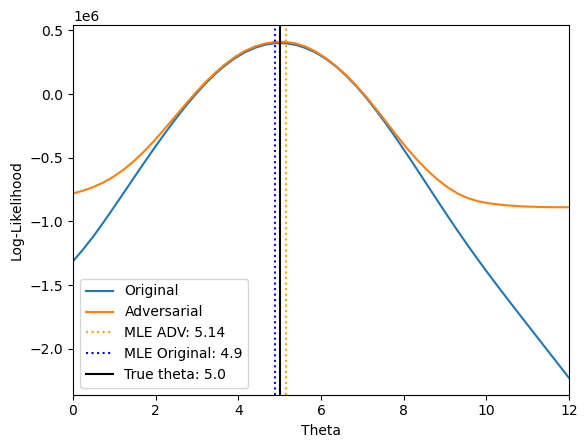

In [92]:
def ratio(x_obs, theta, model):
    X = torch.cat([x_obs, theta], dim=1)
    logits = model(X)
    s = torch.sigmoid(logits)
    r = s / (1 - s)
    return r

def log_likelihood(theta, X_obs, model):
    # X_obs: shape [N, x_dim]
    thetas = theta.unsqueeze(0).expand(len(X_obs), -1)
    r_vals = ratio(X_obs, thetas, model)
    return torch.sum(torch.log(r_vals))


def ratio_adv(x_obs, theta, encoder, classifier_head):
    z = encoder(x_obs)
    X = torch.cat([z, theta], dim=1)
    logits = classifier_head(X)
    s = torch.sigmoid(logits)
    r = s / (1 - s)
    return r

def log_likelihood_adv(theta, X_obs, encoder, classifier_head):
    # X_obs: shape [N, x_dim]
    thetas = theta.unsqueeze(0).expand(len(X_obs), -1)
    r_vals = ratio_adv(X_obs, thetas, encoder, classifier_head)
    return torch.sum(torch.log(r_vals))


new_data =  np.random.normal(loc = 5, scale = 1.0, size = (n_signal_events, n_gaussian_dim)).astype(np.float32)
new_data = np.concatenate((new_data, np.full((n_signal_events, 1), fill_value=0.0), np.full((n_signal_events, 1), fill_value=11)), axis=1).astype(np.float32)
new_data   = scaler.transform(new_data)
new_data = new_data[:,:-2]
X_obs = torch.tensor(new_data, requires_grad=False)


def plot_log_likelihoods(X_obs, true_theta, range, model, encoder, classifier_head):

    log_likelihoods = []
    log_likelihoods_adv = []
    x = np.linspace(range[0],range[1],50)
    for ix in x:
        theta_tensor = torch.tensor([min_max_scaler(min_theta, max_theta, ix)], requires_grad=False, dtype=torch.float32)
        llh = log_likelihood(theta_tensor, X_obs, model)
        llh_adv = log_likelihood_adv(theta_tensor, X_obs, encoder, classifier_head)
        log_likelihoods.append(llh.item())
        log_likelihoods_adv.append(llh_adv.item())

    plt.plot(x, log_likelihoods, label="Original")
    plt.plot(x, log_likelihoods_adv, label="Adversarial")
    
    mle_adv = x[np.argmax(log_likelihoods_adv)]
    mle = x[np.argmax(log_likelihoods)]
    plt.axvline(mle_adv, color='orange', linestyle='dotted', label=f'MLE ADV: {round(mle_adv,2)}')
    plt.axvline(mle, color='blue', linestyle='dotted', label=f'MLE Original: {round(mle,2)}')
    plt.axvline(true_theta, color='black', linestyle='solid', label=f'True theta: {round(true_theta,2)}')
    

    
    plt.xlabel("Theta")
    plt.ylabel("Log-Likelihood")
    plt.xlim((min(x),max(x)))
    plt.legend()
    plt.show()

plot_log_likelihoods(X_obs, 5.0, [0.0,12.0], model, encoder, classifier_head)

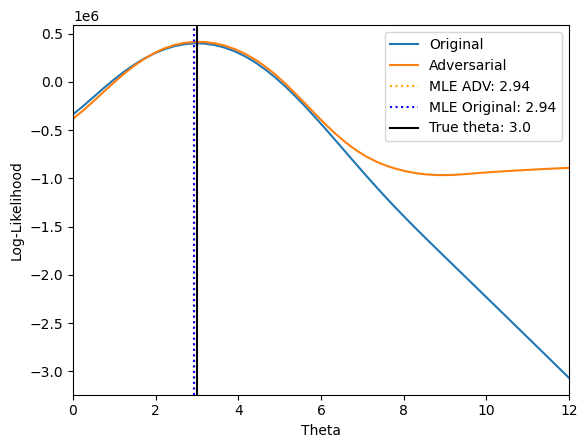

In [93]:
new_data =  np.random.normal(loc = 3, scale = 1.0, size = (n_signal_events, n_gaussian_dim)).astype(np.float32)
new_data = np.concatenate((new_data, np.full((n_signal_events, 1), fill_value=0.0), np.full((n_signal_events, 1), fill_value=11)), axis=1).astype(np.float32)
new_data   = scaler.transform(new_data)
new_data = new_data[:,:-2]
X_obs = torch.tensor(new_data, requires_grad=False)

plot_log_likelihoods(X_obs, 3.0, [0.0,12.0], model, encoder, classifier_head)

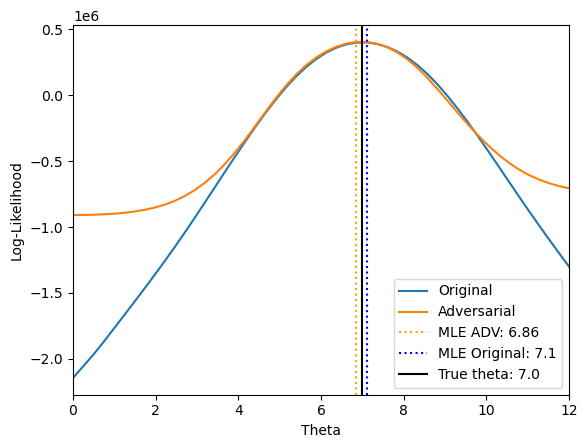

In [94]:
new_data =  np.random.normal(loc = 7, scale = 1.0, size = (n_signal_events, n_gaussian_dim)).astype(np.float32)
new_data = np.concatenate((new_data, np.full((n_signal_events, 1), fill_value=0.0), np.full((n_signal_events, 1), fill_value=11)), axis=1).astype(np.float32)
new_data   = scaler.transform(new_data)
new_data = new_data[:,:-2]
X_obs = torch.tensor(new_data, requires_grad=False)

plot_log_likelihoods(X_obs, 7.0, [0.0,12.0], model, encoder, classifier_head)

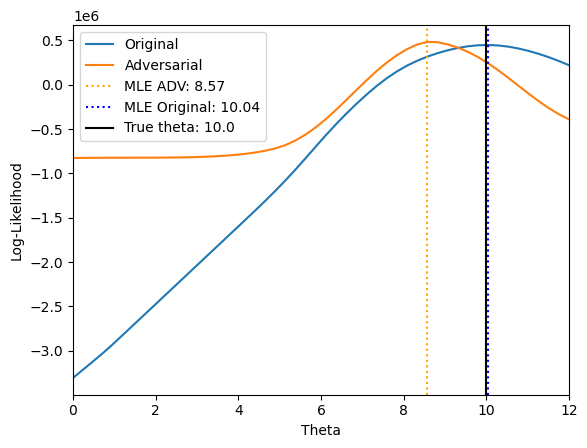

In [95]:
new_data =  np.random.normal(loc = 10, scale = 1.0, size = (n_signal_events, n_gaussian_dim)).astype(np.float32)
new_data = np.concatenate((new_data, np.full((n_signal_events, 1), fill_value=0.0), np.full((n_signal_events, 1), fill_value=11)), axis=1).astype(np.float32)
new_data   = scaler.transform(new_data)
new_data = new_data[:,:-2]
X_obs = torch.tensor(new_data, requires_grad=False)

plot_log_likelihoods(X_obs, 10.0, [0.0,12.0], model, encoder, classifier_head)

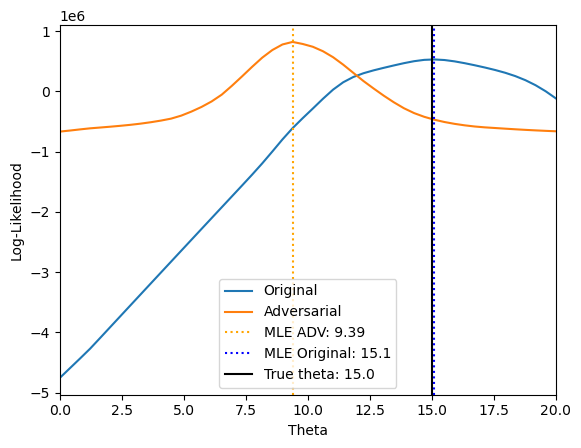

In [96]:
new_data =  np.random.normal(loc = 15, scale = 1.0, size = (n_signal_events, n_gaussian_dim)).astype(np.float32)
new_data = np.concatenate((new_data, np.full((n_signal_events, 1), fill_value=0.0), np.full((n_signal_events, 1), fill_value=11)), axis=1).astype(np.float32)
new_data   = scaler.transform(new_data)
new_data = new_data[:,:-2]
X_obs = torch.tensor(new_data, requires_grad=False)

plot_log_likelihoods(X_obs, 15.0, [0.0,20.0], model, encoder, classifier_head)